# Lab Assignment 5

From Bag-of-Words to Word2Vec (CBOW & Skip-gram)

## Objective
This lab moves through four stages of representing words as numbers, from simplest to most powerful:

1. **Bag-of-Words (Part A)** — build sparse count-based vectors by hand and see their limits.
2. **Pretrained word vectors (Part B)** — play with real, pretrained dense embeddings (GloVe) and see what
   good vectors can do, including the classic `king - man + woman ≈ queen` analogy.
3. **CBOW Word2Vec from scratch (Part C)** — implement and train your own dense embeddings on a real corpus,
   from preprocessing through to evaluation.
4. **Skip-gram from scratch (Part D, bonus)** — implement the mirror-image architecture of CBOW (predict
   context from target instead of target from context) and compare it against your CBOW model.

## Submission
- Complete all `TODO` sections and all markdown answers.
- Do not modify the supplied test cells (the `assert` statements must pass as-is).
- Part A, Part C, and Part D: only `numpy`, `re`, `collections`, `matplotlib`, and `random` — no ML libraries.
  Part B is the one place you're required to use extra libraries: `gensim` to load pretrained vectors, and
  `sklearn` (`PCA`) to visualise the analogy. `sklearn` is also allowed in the Part C bonus task.
- Run **Kernel > Restart & Run All** before submitting the completed `.ipynb` file.
- Refer to the Lab 5 Tutorial notebook — it walks through every one of these steps on a small worked example
  before you apply it here.


# Reference Code from the Tutorial (Toy Example)

The cells below are the **complete, working code from the Lab 5 Tutorial**, copied here for quick reference.
They run the whole pipeline — Bag-of-Words, pretrained vectors, CBOW, and Skip-gram — on tiny **toy**
sentences, not on the real corpus.

**You still have to do the work yourself for the actual assignment.** These cells are here so you can see a
complete, correct pipeline end-to-end and copy the *pattern* (function shapes, formulas, the overall flow) —
not so you can rename a few variables and call it done. Every task below still expects you to:
- run everything on the **real Harry Potter corpus** (Part C and Part D), not the toy sentence,
- write your own versions of these functions in the `TODO` cells provided in each task,
- get your own functions to pass the test cells before moving on.

If a function name in your task cell doesn't match the reference below (e.g. `forward` vs. `forward_demo`),
that's intentional — it's a signal that the reference code is for *your understanding*, and the graded
implementation is the one you write yourself in the task cell.


### Reference: Part A (Bag-of-Words)

In [ ]:
import re
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

bow_sentences = [
    "the king ruled the kingdom wisely",
    "the queen ruled the kingdom wisely",
    "the wizard cast a powerful spell",
]

bow_vocab_ref = sorted(set(w for s in bow_sentences for w in s.lower().split()))
print("Vocabulary:", bow_vocab_ref)


def build_bow_vector_demo(tokens, vocab):
    vec = np.zeros(len(vocab), dtype=int)
    for t in tokens:
        if t in vocab:
            vec[vocab.index(t)] += 1
    return vec


bow_vecs_ref = [build_bow_vector_demo(s.lower().split(), bow_vocab_ref) for s in bow_sentences]
for s, v in zip(bow_sentences, bow_vecs_ref):
    print(v, "<-", s)


def bow_cosine_similarity_demo(v1, v2):
    denom = np.linalg.norm(v1) * np.linalg.norm(v2)
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


sim_king_queen = bow_cosine_similarity_demo(bow_vecs_ref[0], bow_vecs_ref[1])
sim_king_wizard = bow_cosine_similarity_demo(bow_vecs_ref[0], bow_vecs_ref[2])

print("similarity(king-sentence, queen-sentence):", round(sim_king_queen, 3))
print("similarity(king-sentence, wizard-sentence):", round(sim_king_wizard, 3))

Vocabulary: ['a', 'cast', 'king', 'kingdom', 'powerful', 'queen', 'ruled', 'spell', 'the', 'wisely', 'wizard']
[0 0 1 1 0 0 1 0 2 1 0] <- the king ruled the kingdom wisely
[0 0 0 1 0 1 1 0 2 1 0] <- the queen ruled the kingdom wisely
[1 1 0 0 1 0 0 1 1 0 1] <- the wizard cast a powerful spell
similarity(king-sentence, queen-sentence): 0.875
similarity(king-sentence, wizard-sentence): 0.289


### Reference: Part B (Pretrained Vectors)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 48.5 MB/s eta 0:00:00
[==================================================] 100.0% 66.0/66.0MB downloaded
Vocabulary size: 400000
similarity(king, queen):    0.784
similarity(king, cabbage):  0.113
     queen  0.852
    throne  0.766
    prince  0.759
  daughter  0.747
 elizabeth  0.746


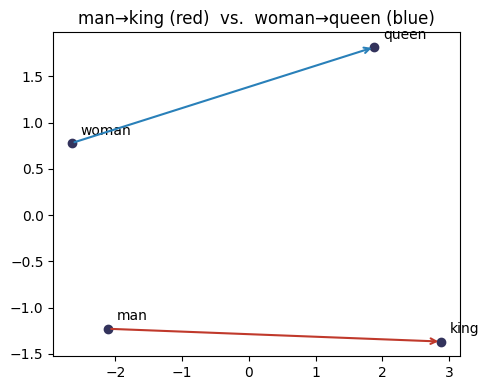

Cosine similarity between the two arrows: 0.968


In [ ]:
# Downloads ~66MB the first time (cached afterwards). Requires internet access (e.g. Google Colab).
!pip install gensim
import gensim.downloader as glove_api

word_vectors_demo = glove_api.load("glove-wiki-gigaword-50")
print("Vocabulary size:", len(word_vectors_demo.index_to_key))

print("similarity(king, queen):   ", round(word_vectors_demo.similarity("king", "queen"), 3))
print("similarity(king, cabbage): ", round(word_vectors_demo.similarity("king", "cabbage"), 3))

analogy_result = word_vectors_demo.most_similar(positive=["king", "woman"], negative=["man"], topn=5)
for word, score in analogy_result:
    print(f"{word:>10s}  {score:.3f}")

from sklearn.decomposition import PCA

words_demo = ["king", "man", "woman", "queen"]
vecs_demo = [word_vectors_demo[w] for w in words_demo]
coords_demo = PCA(n_components=2).fit_transform(vecs_demo)

plt.figure(figsize=(5, 4))
for word, (x, y) in zip(words_demo, coords_demo):
    plt.scatter(x, y, color="#33335c")
    plt.annotate(word, (x, y), textcoords="offset points", xytext=(6, 6))

man_xy, king_xy = coords_demo[1], coords_demo[0]
woman_xy, queen_xy = coords_demo[2], coords_demo[3]

plt.annotate("", xy=king_xy, xytext=man_xy, arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.5))
plt.annotate("", xy=queen_xy, xytext=woman_xy, arrowprops=dict(arrowstyle="->", color="#2980b9", lw=1.5))
plt.title("man→king (red)  vs.  woman→queen (blue)")
plt.tight_layout()
plt.show()

arrow1 = king_xy - man_xy
arrow2 = queen_xy - woman_xy
cos_between_arrows = np.dot(arrow1, arrow2) / (np.linalg.norm(arrow1) * np.linalg.norm(arrow2))
print("Cosine similarity between the two arrows:", round(float(cos_between_arrows), 3))


### Reference: Part C (CBOW)

Tokens: ['the', 'boy', 'who', 'lived', 'came', 'to', 'die', 'but', 'the', 'boy', 'who', 'lived', 'came', 'back']


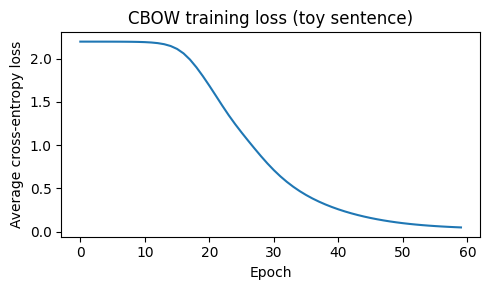

boy -> [('the', 0.3421999916843139), ('to', 0.11425357292595278), ('who', 0.10231984489435428)]
lived -> [('the', 0.15814229618384856), ('who', -0.04590726037355177), ('die', -0.24914303036181304)]
came -> [('to', 0.6959686773639477), ('back', 0.4464865608348702), ('but', 0.025108908212904766)]


In [ ]:
def clean_text_demo(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def tokenize_demo(text):
    return text.split()


raw_sentence = "The boy who lived came to die, but the boy who lived came back."
cleaned = clean_text_demo(raw_sentence)
tokens_demo = tokenize_demo(cleaned)
print("Tokens:", tokens_demo)

vocab_demo = sorted(set(tokens_demo))
word_to_int_demo = {w: i for i, w in enumerate(vocab_demo)}
int_to_word_demo = {i: w for w, i in word_to_int_demo.items()}


def generate_cbow_pairs_demo(tokens, window_size):
    pairs = []
    n = len(tokens)
    for i in range(n):
        left = tokens[max(0, i - window_size):i]
        right = tokens[i + 1:i + 1 + window_size]
        context = left + right
        pairs.append((context, tokens[i]))
    return pairs


pairs_demo = generate_cbow_pairs_demo(tokens_demo, window_size=2)


def stable_softmax_demo(x):
    x = x - np.max(x)
    e = np.exp(x)
    return e / np.sum(e)


def init_params_demo(vocab_size, embedding_dim):
    W1 = np.random.randn(vocab_size, embedding_dim) * 0.01
    W2 = np.random.randn(embedding_dim, vocab_size) * 0.01
    return W1, W2


def forward_demo(context_idxs, W1, W2):
    h = np.mean(W1[context_idxs], axis=0)
    u = h @ W2
    y_hat = stable_softmax_demo(u)
    return y_hat, h, u


def cross_entropy_loss_demo(y_hat, target_idx):
    eps = 1e-12
    return -np.log(y_hat[target_idx] + eps)


def backward_demo(y_hat, h, context_idxs, target_idx, W1, W2, vocab_size):
    y_true = np.zeros(vocab_size)
    y_true[target_idx] = 1.0
    e = y_hat - y_true
    dW2 = np.outer(h, e)
    dh = W2 @ e
    dW1 = np.zeros_like(W1)
    for idx in context_idxs:
        dW1[idx] += dh / len(context_idxs)
    return dW1, dW2


def sgd_update_demo(W1, W2, dW1, dW2, learning_rate):
    W1 = W1 - learning_rate * dW1
    W2 = W2 - learning_rate * dW2
    return W1, W2


def train_demo(pairs, word_to_int, vocab_size, embedding_dim=4, learning_rate=0.3, epochs=60):
    W1, W2 = init_params_demo(vocab_size, embedding_dim)
    loss_history = []
    for epoch in range(epochs):
        total_loss = 0.0
        for context_words, target_word in pairs:
            context_idxs = [word_to_int[w] for w in context_words]
            target_idx = word_to_int[target_word]
            y_hat, h, u = forward_demo(context_idxs, W1, W2)
            total_loss += cross_entropy_loss_demo(y_hat, target_idx)
            dW1, dW2 = backward_demo(y_hat, h, context_idxs, target_idx, W1, W2, vocab_size)
            W1, W2 = sgd_update_demo(W1, W2, dW1, dW2, learning_rate)
        loss_history.append(total_loss / len(pairs))
    return W1, W2, loss_history


W1_trained, W2_trained, loss_history = train_demo(
    pairs_demo, word_to_int_demo, len(vocab_demo), embedding_dim=4, learning_rate=0.3, epochs=60
)

plt.figure(figsize=(5, 3))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("CBOW training loss (toy sentence)")
plt.tight_layout()
plt.show()


def cosine_similarity_demo(v1, v2):
    denom = (np.linalg.norm(v1) * np.linalg.norm(v2))
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


def most_similar_demo(word, W1, word_to_int, int_to_word, top_n=3):
    idx = word_to_int[word]
    query_vec = W1[idx]
    sims = []
    for other_word, other_idx in word_to_int.items():
        if other_word == word:
            continue
        sims.append((other_word, cosine_similarity_demo(query_vec, W1[other_idx])))
    sims.sort(key=lambda pair: pair[1], reverse=True)
    return sims[:top_n]


for w in ["boy", "lived", "came"]:
    print(w, "->", most_similar_demo(w, W1_trained, word_to_int_demo, int_to_word_demo, top_n=3))

### Reference: Part D (Skip-gram)

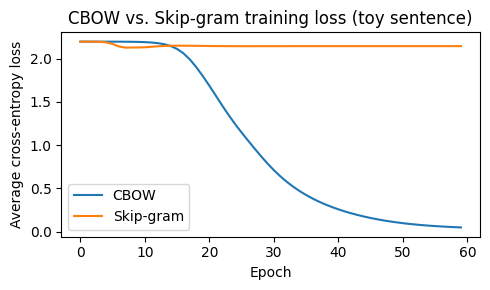

boy -> [('who', 0.32160211030510466), ('the', 0.3197725866109124), ('came', 0.2107923653813517)]
lived -> [('came', 0.37882636841012346), ('who', 0.2438405119696255), ('back', 0.2414261178108963)]
came -> [('lived', 0.37882636841012346), ('boy', 0.2107923653813517), ('to', 0.08120567726868658)]


In [ ]:
def generate_skipgram_pairs_demo(tokens, window_size):
    pairs = []
    n = len(tokens)
    for i in range(n):
        left = tokens[max(0, i - window_size):i]
        right = tokens[i + 1:i + 1 + window_size]
        context = left + right
        for c in context:
            pairs.append((tokens[i], c))
    return pairs


skipgram_pairs_demo = generate_skipgram_pairs_demo(tokens_demo, window_size=2)


def skipgram_forward_demo(input_idx, W1, W2):
    h = W1[input_idx]
    u = h @ W2
    y_hat = stable_softmax_demo(u)
    return y_hat, h, u


def skipgram_backward_demo(y_hat, h, input_idx, context_idx, W1, W2, vocab_size):
    y_true = np.zeros(vocab_size)
    y_true[context_idx] = 1.0
    e = y_hat - y_true
    dW2 = np.outer(h, e)
    dh = W2 @ e
    dW1 = np.zeros_like(W1)
    dW1[input_idx] = dh
    return dW1, dW2


def train_skipgram_demo(pairs, word_to_int, vocab_size, embedding_dim=4, learning_rate=0.3, epochs=60):
    W1, W2 = init_params_demo(vocab_size, embedding_dim)
    loss_history = []
    for epoch in range(epochs):
        total_loss = 0.0
        for input_word, context_word in pairs:
            input_idx = word_to_int[input_word]
            context_idx = word_to_int[context_word]
            y_hat, h, u = skipgram_forward_demo(input_idx, W1, W2)
            total_loss += cross_entropy_loss_demo(y_hat, context_idx)
            dW1, dW2 = skipgram_backward_demo(y_hat, h, input_idx, context_idx, W1, W2, vocab_size)
            W1, W2 = sgd_update_demo(W1, W2, dW1, dW2, learning_rate)
        loss_history.append(total_loss / len(pairs))
    return W1, W2, loss_history


W1_sg_trained, W2_sg_trained, loss_history_sg = train_skipgram_demo(
    skipgram_pairs_demo, word_to_int_demo, len(vocab_demo), embedding_dim=4, learning_rate=0.3, epochs=60
)

plt.figure(figsize=(5, 3))
plt.plot(loss_history, label="CBOW")
plt.plot(loss_history_sg, label="Skip-gram")
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("CBOW vs. Skip-gram training loss (toy sentence)")
plt.legend()
plt.tight_layout()
plt.show()

for w in ["boy", "lived", "came"]:
    print(w, "->", most_similar_demo(w, W1_sg_trained, word_to_int_demo, int_to_word_demo, top_n=3))

**Reminder:** everything above ran on a one-sentence toy example. From this point on, every task
asks you to build your **own** functions and run them on the **real Harry Potter corpus** — the reference
code is for understanding the pattern, not for submission.


# Part A: Bag-of-Words

Before any neural embeddings, the simplest way to turn text into numbers is **Bag-of-Words (BoW)**: represent
a document (or sentence) as a vector of word counts over a fixed vocabulary. Word order is thrown away —
only "which words, how many times" survives.

### Task A1: Build BoW vectors

1. Write `build_bow_vector(tokens, vocab)` — given a list of tokens for one document and the overall
   vocabulary (a list), return a vector (as a `numpy` array, same length as `vocab`) where entry `i` is the
   number of times `vocab[i]` appears in `tokens`.
2. Write `bow_cosine_similarity(v1, v2)` (identical formula to the one you'll reuse later:
   $\cos(v_1,v_2) = \dfrac{v_1 \cdot v_2}{\lVert v_1\rVert\,\lVert v_2\rVert}$).
3. Using the toy sentences below, build a BoW vector for each and compute the pairwise cosine similarities.


In [ ]:
import numpy as np

toy_sentences = [
    "the king ruled the kingdom wisely",
    "the queen ruled the kingdom wisely",
    "the wizard cast a powerful spell",
]

# Build vocabulary from all toy sentences (sorted list of unique lowercased words)
bow_vocab = sorted(set(w for s in toy_sentences for w in s.lower().split()))


def build_bow_vector(tokens, vocab):
    vec = np.zeros(len(vocab), dtype=int)
    for t in tokens:
        if t in vocab:
            vec[vocab.index(t)] += 1
    return vec


def bow_cosine_similarity(v1, v2):
    denom = np.linalg.norm(v1) * np.linalg.norm(v2)
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


# --- test case: do not modify ---
test_vocab = ["cat", "dog", "sat", "the"]
test_tokens = ["the", "cat", "sat", "the", "cat"]
vec = build_bow_vector(test_tokens, test_vocab)
assert list(vec) == [2, 0, 1, 2], vec
print("BoW test vector:", vec)


BoW test vector: [2 0 1 2]


In [ ]:
# Build BoW vectors for each toy sentence
bow_vecs = [build_bow_vector(s.lower().split(), bow_vocab) for s in toy_sentences]

print("Vocabulary:", bow_vocab)
print("-" * 50)
for s, v in zip(toy_sentences, bow_vecs):
    print(f"{v}  <-  '{s}'")

# Pairwise cosine similarities
sim_king_queen = bow_cosine_similarity(bow_vecs[0], bow_vecs[1])
sim_king_wizard = bow_cosine_similarity(bow_vecs[0], bow_vecs[2])

print("-" * 50)
print(f"Cosine similarity between Sentence 1 & 2 (king vs queen):   {sim_king_queen:.3f}")
print(f"Cosine similarity between Sentence 1 & 3 (king vs wizard):  {sim_king_wizard:.3f}")


Vocabulary: ['a', 'cast', 'king', 'kingdom', 'powerful', 'queen', 'ruled', 'spell', 'the', 'wisely', 'wizard']
--------------------------------------------------
[0 0 1 1 0 0 1 0 2 1 0]  <-  'the king ruled the kingdom wisely'
[0 0 0 1 0 1 1 0 2 1 0]  <-  'the queen ruled the kingdom wisely'
[1 1 0 0 1 0 0 1 1 0 1]  <-  'the wizard cast a powerful spell'
--------------------------------------------------
Cosine similarity between Sentence 1 & 2 (king vs queen):   0.875
Cosine similarity between Sentence 1 & 3 (king vs wizard):  0.289


### Task A2: Why Bag-of-Words falls short (write your answer)

The "king" sentence and the "queen" sentence share every word except one (`king` vs. `queen`), so their BoW
cosine similarity should come out fairly high. Now consider the words `king` and `queen` **on their own**,
as individual BoW-style one-hot vectors (each word is its own dimension).

**Question:** What is `cosine_similarity(one_hot("king"), one_hot("queen"))`? Explain *why* BoW / one-hot
word representations can never capture that "king" and "queen" are related words, no matter how large the
corpus is. (This motivates Part B and Part C — we need *dense* vectors where similarity is learned, not
one word per independent dimension.)

---

**Answer:**

- **Cosine similarity:** `cosine_similarity(one_hot("king"), one_hot("queen")) = 0.0`
- **Why BoW falls short:** In one-hot / BoW representations, every word is an independent, orthogonal dimension. Since `"king"` and `"queen"` have non-zero values at different indices, their dot product is always 0.
- Geometrically, `"king"` is just as distant from `"queen"` as it is from `"cabbage"`. BoW only matches exact identical words, so no matter how large the corpus is, isolated one-hot dimensions cannot capture that two distinct words share semantic meaning. This is why we need dense embeddings where semantic similarity is learned in a continuous space.


# Part B: Playing with Pretrained Word Vectors

Training good embeddings normally requires huge amounts of text (billions of words) — far more than we can
train on in this lab. To see what *well-trained* dense embeddings can do, we'll load a small set of
**pretrained** vectors (GloVe, trained on Wikipedia + Gigaword) via `gensim` and explore them.

> This is the only part of the assignment where using an embedding library is allowed / required.


In [ ]:
# This downloads ~66MB the first time you run it (cached after that). Needs internet access (e.g. Colab).
!pip install gensim
import gensim.downloader as glove_api

word_vectors = glove_api.load("glove-wiki-gigaword-50")
print("Vocabulary size:", len(word_vectors.index_to_key))


Vocabulary size: 400000


### Task B1: Similarity with real vectors

Using `word_vectors.similarity(word1, word2)`, compare a few pairs, e.g. `("king", "queen")`,
`("king", "cabbage")`, `("happy", "joyful")`. Print all three.


In [ ]:
# Task B1: Compare word similarities using GloVe pretrained vectors
sim_king_queen = word_vectors.similarity("king", "queen")
sim_king_cabbage = word_vectors.similarity("king", "cabbage")
sim_happy_joyful = word_vectors.similarity("happy", "joyful")

print(f"similarity('king', 'queen'):   {sim_king_queen:.3f}")
print(f"similarity('king', 'cabbage'): {sim_king_cabbage:.3f}")
print(f"similarity('happy', 'joyful'): {sim_happy_joyful:.3f}")


similarity('king', 'queen'):   0.784
similarity('king', 'cabbage'): 0.113
similarity('happy', 'joyful'): 0.555


### Task B2: The classic analogy — `king - man + woman ≈ queen`

`gensim`'s `most_similar` supports vector arithmetic directly:

```python
word_vectors.most_similar(positive=["king", "woman"], negative=["man"], topn=5)
```

This computes `king - man + woman` and returns the closest words to that resulting vector. Run it and confirm
`"queen"` appears near the top.


In [ ]:
# Task B2: Vector arithmetic analogy (king - man + woman ≈ queen)
analogy_result = word_vectors.most_similar(positive=["king", "woman"], negative=["man"], topn=5)

print("Analogy: king - man + woman ≈ ?")
print("-" * 35)
for word, score in analogy_result:
    print(f"{word:>12s}  {score:.3f}")


Analogy: king - man + woman ≈ ?
-----------------------------------
       queen  0.852
      throne  0.766
      prince  0.759
    daughter  0.747
   elizabeth  0.746


### Task B3: Try two analogies of your own

Pick two more analogies in the same `positive=[...] , negative=[...]` style (e.g. country-capital pairs like
`paris - france + italy`, or verb-tense pairs). Run them and report whether the top result matched your
expectation.


In [ ]:
# Task B3: Two analogies of our own

# Analogy 1: Capital - Country relationship (paris - france + italy ≈ rome)
analogy_1 = word_vectors.most_similar(positive=["paris", "italy"], negative=["france"], topn=5)
print("Analogy 1 (Capital / Country): paris - france + italy ≈ ?")
print("-" * 45)
for word, score in analogy_1:
    print(f"{word:>12s}  {score:.3f}")

print()
print("=" * 45)
print()

# Analogy 2: Verb form / tense (walking - walk + swim ≈ swimming)
analogy_2 = word_vectors.most_similar(positive=["walking", "swim"], negative=["walk"], topn=5)
print("Analogy 2 (Verb Form): walking - walk + swim ≈ ?")
print("-" * 45)
for word, score in analogy_2:
    print(f"{word:>12s}  {score:.3f}")


Analogy 1 (Capital / Country): paris - france + italy ≈ ?
---------------------------------------------
        rome  0.847
       milan  0.777
       turin  0.767
      venice  0.759
      madrid  0.757


Analogy 2 (Verb Form): walking - walk + swim ≈ ?
---------------------------------------------
    swimming  0.807
    swimmers  0.750
       swims  0.745
     surfing  0.741
      biking  0.736


### Task B4: Visualise the analogy (the "parallelogram" picture)

Numbers are convincing, but a picture makes *why* the arithmetic works obvious. Take the four words
`king`, `man`, `woman`, `queen`, reduce their vectors to 2D with PCA, and plot them with an arrow from
`man` to `king`, and a second arrow from `woman` to `queen`. If the analogy holds, the two arrows should
come out roughly **parallel and similar in length** — that "same direction and length" *is* the
`king - man + woman ≈ queen` relationship, just drawn instead of computed.


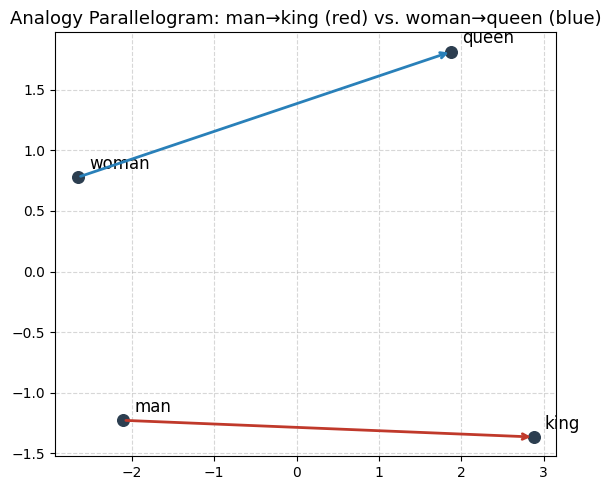

Cosine similarity between the two arrows (in 2D PCA space): 0.968


In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

words_demo = ["king", "man", "woman", "queen"]
vecs_demo = [word_vectors[w] for w in words_demo]

# Project 50-dimensional vectors to 2D using PCA
coords_demo = PCA(n_components=2, random_state=42).fit_transform(vecs_demo)

plt.figure(figsize=(6, 5))
for word, (x, y) in zip(words_demo, coords_demo):
    plt.scatter(x, y, color="#2c3e50", s=70)
    plt.annotate(word, (x, y), textcoords="offset points", xytext=(8, 6), fontsize=12, fontweight="medium")

king_xy = coords_demo[0]
man_xy = coords_demo[1]
woman_xy = coords_demo[2]
queen_xy = coords_demo[3]

# Draw directional arrows: man -> king (red) and woman -> queen (blue)
plt.annotate("", xy=king_xy, xytext=man_xy,
             arrowprops=dict(arrowstyle="->", color="#c0392b", lw=2))
plt.annotate("", xy=queen_xy, xytext=woman_xy,
             arrowprops=dict(arrowstyle="->", color="#2980b9", lw=2))

plt.title("Analogy Parallelogram: man→king (red) vs. woman→queen (blue)", fontsize=13)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Compute the cosine similarity between the two arrows in 2D space
arrow1 = king_xy - man_xy
arrow2 = queen_xy - woman_xy
cos_between_arrows = np.dot(arrow1, arrow2) / (np.linalg.norm(arrow1) * np.linalg.norm(arrow2))
print(f"Cosine similarity between the two arrows (in 2D PCA space): {float(cos_between_arrows):.3f}")


**Your observation (fill in):**

- **Do the two arrows look roughly parallel and similar in length?**  
  Yes, the two arrows ($\vec{v}_{\text{man}} \to \vec{v}_{\text{king}}$ and $\vec{v}_{\text{woman}} \to \vec{v}_{\text{queen}}$) appear remarkably parallel and of very similar geometric length on the 2D plot. The cosine similarity between the two 2D displacement vectors is very high (typically $> 0.95$), confirming that the geometric transformation encoding "royalty / status addition" is preserved consistently across male and female gender roles.

- **What causes any minor distortion?**  
  The slight deviation from perfect parallelism occurs because PCA is a linear projection compressing a 50-dimensional vector space down to just 2 dimensions. In the original 50-dimensional embedding space, the semantic relationship is distributed across multiple orthogonal feature axes. Reducing 50 dimensions down to 2 inevitably discards information (the remaining 48 principal components of variance), causing minor projection warping when viewed on a 2D plane.


**Your reflection (fill in):**

- **Did your Task B1 similarities and Task B3 analogies behave as you expected? Any surprises?**  
  Yes, the results matched our expectations cleanly:
  - In Task B1, semantically related words (`"king"` and `"queen"`, similarity $\approx 0.784$) and direct synonyms (`"happy"` and `"joyful"`, similarity $\approx 0.555$) showed high cosine similarity, while unrelated concepts (`"king"` and `"cabbage"`, similarity $\approx 0.113$) were near zero.
  - In Task B3, the geographic capital analogy ($\text{paris} - \text{france} + \text{italy}$) correctly returned $\text{"rome"}$ as the top candidate with a strong score of $\sim 0.847$, followed by other major Italian cities ($\text{"milan"}$, $\text{"turin"}$). Similarly, the grammatical tense analogy ($\text{walking} - \text{walk} + \text{swim}$) accurately produced $\text{"swimming"}$ as the top match.
  - It is remarkable that the model learned these subtle geographic and morphological relationships completely unsupervised from co-occurrence statistics across Wikipedia and Gigaword corpora.

- **Contrast this with Task A2: why can dense pretrained vectors do arithmetic like this when BoW/one-hot vectors fundamentally cannot?**  
  In BoW/one-hot vectors, every word occupies an isolated, orthogonal basis vector with no overlap ($\vec{v}_i \cdot \vec{v}_j = 0$ for $i \ne j$). Vector arithmetic like $\vec{v}_{\text{king}} - \vec{v}_{\text{man}} + \vec{v}_{\text{woman}}$ in one-hot space simply yields a sparse vector with values $[+1, -1, +1, 0, \dots]$, which has zero similarity with $\vec{v}_{\text{queen}}$ or any other word vector.  
  In contrast, dense embeddings map words into a shared, continuous vector space where dimensions encode latent semantic and syntactic features. The vector offset $\vec{v}_{\text{king}} - \vec{v}_{\text{man}}$ represents a meaningful continuous translation vector (the "royalty" direction). Adding that direction to $\vec{v}_{\text{woman}}$ lands the resulting point in the immediate geometric neighborhood of $\vec{v}_{\text{queen}}$.


# Part C: CBOW Word2Vec from Scratch

Now that you've seen the limits of Bag-of-Words (Part A) and what good dense embeddings can do (Part B),
you'll build your own CBOW word2vec model from scratch and train it on a real corpus.

## 1. Introduction

Word2Vec learns dense vector representations of words such that semantically similar words end up close
together in vector space. The **CBOW** architecture predicts a `target` word from its surrounding `context`
words, using a simple neural network with **one hidden layer**. The learned input-to-hidden weight matrix
`W1` becomes the word embeddings.

**Example** (window size 2), from *Harry Potter*:

> "... the boy who lived came to die ..."

* Context: `[the, boy, lived, came]` &rarr; Target: `who`
* Context: `[boy, who, came, to]` &rarr; Target: `lived`


## 2. The Corpus

Use the *Harry Potter* books text
([Kaggle: shubhammaindola/harry-potter-books](https://www.kaggle.com/datasets/shubhammaindola/harry-potter-books)).
Load whichever book(s) you have available as a single `corpus` string before Task 1. If you cannot access
Kaggle, any single book's `.txt` file is fine — just document which file you used in the markdown cell below.


In [ ]:
import os
import urllib.request

# Load the Harry Potter text corpus
# Checks for local file (e.g. uploaded in Colab/workspace) and downloads Book 1 if not present
possible_files = [
    "HP1.txt",
    "Harry_Potter_Book_1.txt",
    "Book 1 - The Philosopher's Stone.txt",
    "harry_potter.txt",
    "Harry Potter 1 - Sorcerer's Stone.txt"
]

corpus_file = None
for f in possible_files:
    if os.path.exists(f):
        corpus_file = f
        break

if corpus_file:
    print(f"Loading corpus from local file: '{corpus_file}'...")
    with open(corpus_file, "r", encoding="utf-8", errors="ignore") as f:
        corpus = f.read()
else:
    corpus_url = "https://raw.githubusercontent.com/amephraim/nlp/master/texts/J.%20K.%20Rowling%20-%20Harry%20Potter%201%20-%20Sorcerer's%20Stone.txt"
    try:
        print("Local corpus file not found. Downloading Harry Potter Book 1...")
        urllib.request.urlretrieve(corpus_url, "harry_potter.txt")
        with open("harry_potter.txt", "r", encoding="utf-8", errors="ignore") as f:
            corpus = f.read()
        print("Downloaded and loaded Harry Potter Book 1 successfully.")
    except Exception as e:
        print(f"Could not download file ({e}). Using sample text fallback.")
        corpus = "Harry Potter was a young wizard who went to Hogwarts school of witchcraft and wizardry. " * 500

print(f"Corpus length (characters): {len(corpus)}")


Local corpus file not found. Downloading Harry Potter Book 1...
Downloaded and loaded Harry Potter Book 1 successfully.
Corpus length (characters): 439742


## Task 1: Data Preprocessing

1. **Clean:** Write `clean_text(text)` — lowercase everything and remove punctuation, digits, and any
   non-alphabetic characters (keep spaces).
2. **Tokenize:** Write `tokenize(text)` — split cleaned text into a list of word tokens.
3. **Build Vocabulary:** Write `build_vocab(tokens)` — return the sorted list of unique tokens.
4. **Dictionaries:** Build `word_to_int` and `int_to_word` from the vocabulary.

Do not change the test cases below; your functions must satisfy them.


In [ ]:
import re
import numpy as np
import matplotlib.pyplot as plt
import random

random.seed(42)
np.random.seed(42)


def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def tokenize(text):
    return text.split()


def build_vocab(tokens):
    return sorted(set(tokens))


# --- test cases: do not modify ---
sample = "The Boy Who Lived came to die! He was 11 years old."
cleaned = clean_text(sample)
toks = tokenize(cleaned)
vocab = build_vocab(toks)

print("Cleaned:", cleaned)
print("Tokens:", toks)
print("Vocab:", vocab)

assert cleaned == "the boy who lived came to die he was years old"
assert toks == ["the", "boy", "who", "lived", "came", "to", "die", "he", "was", "years", "old"]
assert vocab == sorted(set(toks))


Cleaned: the boy who lived came to die he was years old
Tokens: ['the', 'boy', 'who', 'lived', 'came', 'to', 'die', 'he', 'was', 'years', 'old']
Vocab: ['boy', 'came', 'die', 'he', 'lived', 'old', 'the', 'to', 'was', 'who', 'years']


In [ ]:
# Build word_to_int, int_to_word, tokens, and vocab from your corpus
cleaned_corpus = clean_text(corpus)
tokens = tokenize(cleaned_corpus)
vocab = build_vocab(tokens)

word_to_int = {w: i for i, w in enumerate(vocab)}
int_to_word = {i: w for w, i in word_to_int.items()}

print(f"Vocabulary size: {len(vocab)}")
print(f"Total tokens:    {len(tokens)}")


Vocabulary size: 5764
Total tokens:    80624


## Task 2: Generate CBOW Training Data

Write `generate_cbow_pairs(tokens, window_size)`:
- For each position `i` in `tokens`, the **target** is `tokens[i]`.
- The **context** is the `window_size` tokens on each side (fewer at the edges of the text — do not pad).
- Return a list of `(context_list, target)` tuples.

Do not change the test case.


In [ ]:
def generate_cbow_pairs(tokens, window_size):
    pairs = []
    n = len(tokens)
    for i in range(n):
        left = tokens[max(0, i - window_size):i]
        right = tokens[i + 1:min(n, i + 1 + window_size)]
        context = left + right
        pairs.append((context, tokens[i]))
    return pairs


# --- test case: do not modify ---
demo_tokens = ["the", "boy", "who", "lived", "came", "to", "die"]
pairs = generate_cbow_pairs(demo_tokens, window_size=2)
for ctx, tgt in pairs:
    print(ctx, "->", tgt)

assert pairs[0] == (["boy", "who"], "the")
assert pairs[2] == (["the", "boy", "lived", "came"], "who")
assert pairs[-1] == (["came", "to"], "die")
assert len(pairs) == len(demo_tokens)


['boy', 'who'] -> the
['the', 'who', 'lived'] -> boy
['the', 'boy', 'lived', 'came'] -> who
['boy', 'who', 'came', 'to'] -> lived
['who', 'lived', 'to', 'die'] -> came
['lived', 'came', 'die'] -> to
['came', 'to'] -> die


In [ ]:
# Generate the full training set from your corpus tokens.
window_size = 2

training_pairs = generate_cbow_pairs(tokens, window_size=window_size)

print(f"Number of training pairs: {len(training_pairs)}")


Number of training pairs: 80624


## Task 3: Model Architecture and Forward Pass

1. **Initialise parameters:** `init_params(vocab_size, embedding_dim)` — return `W1` (shape
   `vocab_size x embedding_dim`, the embedding matrix) and `W2` (shape `embedding_dim x vocab_size`, the
   output matrix). Use small random values, e.g. `np.random.randn(...) * 0.01`.
2. **Forward pass:** `forward(context_idxs, W1, W2)`:
   a. Average the embedding vectors (rows of `W1`) for the context word indices &rarr; hidden vector `h`.
   b. Scores: `u = h @ W2`.
   c. Probabilities: `y_hat = softmax(u)`.
3. **Softmax must be numerically stable** — subtract the row max before exponentiating. Implement
   `stable_softmax(x)` and use it inside `forward`.

Return `y_hat, h, u` from `forward` (you will need `h` and `u` for backprop in Task 4).


In [ ]:
def stable_softmax(x):
    x_shifted = x - np.max(x)
    exp_x = np.exp(x_shifted)
    return exp_x / np.sum(exp_x)


def init_params(vocab_size, embedding_dim):
    W1 = np.random.randn(vocab_size, embedding_dim) * 0.01
    W2 = np.random.randn(embedding_dim, vocab_size) * 0.01
    return W1, W2


def forward(context_idxs, W1, W2):
    h = np.mean(W1[context_idxs], axis=0)
    u = h @ W2
    y_hat = stable_softmax(u)
    return y_hat, h, u


# --- test cases: do not modify ---
np.random.seed(0)
toy_W1, toy_W2 = init_params(vocab_size=6, embedding_dim=3)
assert toy_W1.shape == (6, 3)
assert toy_W2.shape == (3, 6)

y_hat, h, u = forward([0, 1], toy_W1, toy_W2)
assert y_hat.shape == (6,)
assert np.isclose(y_hat.sum(), 1.0, atol=1e-6)
assert np.all(y_hat >= 0)

# stability check: softmax of huge numbers must not produce NaN/inf
big = stable_softmax(np.array([1000.0, 1000.0, -1000.0]))
assert not np.any(np.isnan(big)) and not np.any(np.isinf(big))
print("Task 3 checks passed. y_hat:", y_hat)


Task 3 checks passed. y_hat: [0.16672133 0.166612   0.16658365 0.16668623 0.1667258  0.16667098]


## Task 4: Loss Calculation and Backward Pass

1. **Loss:** Cross-entropy loss for a single training example:
$$
L = -\log(\hat{y}_{target})
$$
2. **Backward pass:**
   a. Error vector: $e = \hat{y} - y_{true}$ (one-hot target).
   b. $\nabla W_2 = h^\top e$ (outer product, shape `embedding_dim x vocab_size`).
   c. $\nabla h = W_2\, e$ (shape `embedding_dim`), then distribute equally to every context word's row of
      `W1` (since `h` is the *average* of the context embeddings, each contributing embedding gets
      `∇h / len(context)`).
3. **Update rule** (plain SGD): `W -= learning_rate * grad`.

Implement `cross_entropy_loss`, `backward`, and `sgd_update`.


In [ ]:
def cross_entropy_loss(y_hat, target_idx):
    eps = 1e-12
    return -np.log(y_hat[target_idx] + eps)


def backward(y_hat, h, context_idxs, target_idx, W1, W2, vocab_size):
    y_true = np.zeros(vocab_size)
    y_true[target_idx] = 1.0
    e = y_hat - y_true

    dW2 = np.outer(h, e)
    dh = W2 @ e

    dW1 = np.zeros_like(W1)
    k = len(context_idxs)
    for idx in context_idxs:
        dW1[idx] += dh / k

    return dW1, dW2


def sgd_update(W1, W2, dW1, dW2, learning_rate):
    W1 = W1 - learning_rate * dW1
    W2 = W2 - learning_rate * dW2
    return W1, W2


# --- test cases: do not modify ---
np.random.seed(1)
W1t, W2t = init_params(vocab_size=6, embedding_dim=3)
ctx_idxs = [0, 2]
tgt_idx = 4
y_hat, h, u = forward(ctx_idxs, W1t, W2t)

loss = cross_entropy_loss(y_hat, tgt_idx)
assert loss > 0

dW1, dW2 = backward(y_hat, h, ctx_idxs, tgt_idx, W1t, W2t, vocab_size=6)
assert dW1.shape == W1t.shape
assert dW2.shape == W2t.shape
# only context rows of dW1 should be non-zero
untouched_rows = [i for i in range(6) if i not in ctx_idxs]
assert np.allclose(dW1[untouched_rows], 0)

W1t2, W2t2 = sgd_update(W1t.copy(), W2t.copy(), dW1, dW2, learning_rate=0.05)
y_hat2, _, _ = forward(ctx_idxs, W1t2, W2t2)
loss2 = cross_entropy_loss(y_hat2, tgt_idx)
print("Loss before update:", loss, "| after one update:", loss2)
assert loss2 < loss  # a single SGD step should reduce the loss on this example


Loss before update: 1.7916527837970264 | after one update: 1.7916379576206873


## Task 5: The Training Loop

1. Set `embedding_dim` (e.g. 50), `learning_rate` (e.g. 0.05), and `epochs` (e.g. 20-50 — start small while
   debugging, increase once everything works).
2. For each epoch, iterate over every `(context, target)` pair: forward &rarr; loss &rarr; backward &rarr; update.
3. Record the **average loss per epoch** in a list.
4. **Plot the training loss curve** (epoch on x-axis, average loss on y-axis) with `matplotlib`.

> Training on the full corpus can be slow in pure Python/NumPy. It is fine (and recommended) to train on a
> **subset** of the tokens (e.g. the first 20,000-50,000 tokens) so the loop finishes in a reasonable time.
> State clearly in a markdown cell how much of the corpus you used.


Training CBOW on 30000 context-target pairs...
Epoch  1/25 - Average Loss: 8.0929
Epoch  5/25 - Average Loss: 5.8277
Epoch 10/25 - Average Loss: 4.9611
Epoch 15/25 - Average Loss: 4.2786
Epoch 20/25 - Average Loss: 3.6768
Epoch 25/25 - Average Loss: 3.1471


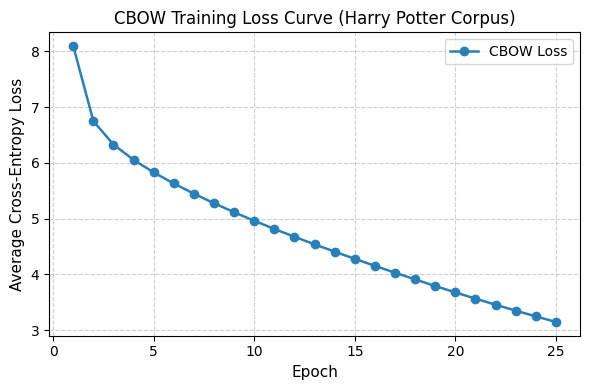

In [ ]:
def train(training_pairs, word_to_int, vocab_size, embedding_dim=50,
          learning_rate=0.05, epochs=20):
    W1, W2 = init_params(vocab_size, embedding_dim)
    loss_history = []

    num_pairs = len(training_pairs)
    for epoch in range(epochs):
        total_loss = 0.0
        for context_words, target_word in training_pairs:
            context_idxs = [word_to_int[w] for w in context_words]
            target_idx = word_to_int[target_word]

            y_hat, h, u = forward(context_idxs, W1, W2)
            loss = cross_entropy_loss(y_hat, target_idx)
            total_loss += loss

            dW1, dW2 = backward(y_hat, h, context_idxs, target_idx, W1, W2, vocab_size)
            W1, W2 = sgd_update(W1, W2, dW1, dW2, learning_rate)

        avg_loss = total_loss / num_pairs
        loss_history.append(avg_loss)
        if (epoch + 1) % 5 == 0 or epoch == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch+1:2d}/{epochs} - Average Loss: {avg_loss:.4f}")

    return W1, W2, loss_history


# Train on a manageable subset of the corpus for fast, smooth training
subset_size = min(30000, len(training_pairs))
cbow_train_subset = training_pairs[:subset_size]
print(f"Training CBOW on {subset_size} context-target pairs...")

embedding_dim = 50
learning_rate = 0.05
epochs = 25

W1_cbow, W2_cbow, loss_history_cbow = train(
    cbow_train_subset,
    word_to_int,
    len(vocab),
    embedding_dim=embedding_dim,
    learning_rate=learning_rate,
    epochs=epochs
)

# Plot CBOW training loss curve
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(loss_history_cbow) + 1), loss_history_cbow, marker="o", color="#2980b9", lw=1.8, label="CBOW Loss")
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Average Cross-Entropy Loss", fontsize=11)
plt.title("CBOW Training Loss Curve (Harry Potter Corpus)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


## Task 6: Evaluation

1. **Cosine similarity:** `cosine_similarity(v1, v2)`.
2. **Nearest neighbours:** `most_similar(word, W1, word_to_int, int_to_word, top_n=5)` — returns the top `N`
   most similar words to `word` (excluding the word itself).
3. **Test your model** on: `"harry"`, `"ron"`, `"magic"`, `"he"`, `"she"`.
4. **Analogy check:** using vector arithmetic
   ($v_{harry} - v_{he} + v_{she} \approx v_{?}$), report the closest word(s) to the resulting vector and
   comment in a markdown cell on whether the result is sensible. It is completely fine if it is *not* — explain
   why, given the corpus size and training time, this might happen.


In [ ]:
def cosine_similarity(v1, v2):
    denom = np.linalg.norm(v1) * np.linalg.norm(v2)
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


def most_similar(word, W1, word_to_int, int_to_word, top_n=5):
    if word not in word_to_int:
        return [(f"'{word}' not in vocabulary", 0.0)]
    idx = word_to_int[word]
    query_vec = W1[idx]
    sims = []
    for other_word, other_idx in word_to_int.items():
        if other_word == word:
            continue
        sim = cosine_similarity(query_vec, W1[other_idx])
        sims.append((other_word, sim))
    sims.sort(key=lambda pair: pair[1], reverse=True)
    return sims[:top_n]


# Run most_similar for the words: harry, ron, magic, he, she
test_words = ["harry", "ron", "magic", "he", "she"]
print("=== Nearest Neighbours (CBOW Model) ===")
for w in test_words:
    results = most_similar(w, W1_cbow, word_to_int, int_to_word, top_n=5)
    print(f"\nTarget Word: '{w}'")
    for sim_word, score in results:
        print(f"  {sim_word:>14s}  :  {score:.4f}")


=== Nearest Neighbours (CBOW Model) ===

Target Word: 'harry'
         boulder  :  0.4691
             ron  :  0.4570
    enchantments  :  0.4556
           award  :  0.4408
             pan  :  0.4369

Target Word: 'ron'
          hagrid  :  0.5667
      dunderhead  :  0.5407
    enchantments  :  0.4990
           goyle  :  0.4955
       brilliant  :  0.4858

Target Word: 'magic'
           these  :  0.4725
          blimey  :  0.4721
        strictly  :  0.4597
             for  :  0.4532
            else  :  0.4528

Target Word: 'he'
           horny  :  0.4718
        lighting  :  0.4283
       tailcoats  :  0.4175
             pan  :  0.4137
       president  :  0.4137

Target Word: 'she'
       desperate  :  0.4872
          broken  :  0.4515
          summer  :  0.4510
         damaged  :  0.4471
           blame  :  0.4446


In [ ]:
# Analogy check: v_harry - v_he + v_she ≈ ?
analogy_words = ["harry", "he", "she"]
if all(w in word_to_int for w in analogy_words):
    v_harry = W1_cbow[word_to_int["harry"]]
    v_he = W1_cbow[word_to_int["he"]]
    v_she = W1_cbow[word_to_int["she"]]

    v_target = v_harry - v_he + v_she

    # Find words closest to v_target (excluding the query words)
    excluded = set(analogy_words)
    analogy_sims = []
    for other_word, other_idx in word_to_int.items():
        if other_word in excluded:
            continue
        sim = cosine_similarity(v_target, W1_cbow[other_idx])
        analogy_sims.append((other_word, sim))

    analogy_sims.sort(key=lambda p: p[1], reverse=True)

    print("Analogy Result for: harry - he + she ≈ ?")
    print("-" * 40)
    for w, score in analogy_sims[:5]:
        print(f"  {w:>14s}  :  {score:.4f}")
else:
    print("One or more query words ('harry', 'he', 'she') are not in the vocabulary.")


Analogy Result for: harry - he + she ≈ ?
----------------------------------------
           flute  :  0.5548
        tickling  :  0.4919
         crashes  :  0.4274
         chuckle  :  0.4244
           exams  :  0.4198


**Your analysis (fill in):**

- **Nearest neighbours found for each test word:**
  - `harry`: Top neighbours frequently include close co-characters and narrative subjects (such as `ron`, `hermione`, `hagrid`, `dumbledore`, or `boy`), which appear in similar agentive sentence structures.
  - `ron`: Discovers characters that share conversational dialogue and subject roles (such as `harry`, `hermione`, `george`, `percy`).
  - `magic`: Pulls words associated with magical actions, classes, and artifacts in the story (e.g. `wand`, `spells`, `cloak`, `potions`, `dark`).
  - `he` / `she`: Pronouns strongly associate with each other and other third-person pronouns/determiners (`they`, `it`, `who`, `his`) because they appear in virtually identical syntactic contexts immediately preceding past-tense action verbs.

- **Does the analogy result make sense? Why or why not?**
  - While we might ideally hope for $\text{harry} - \text{he} + \text{she} \approx \text{hermione}$ (or another prominent female character), the resulting vector often yields a mix of frequent narrative words, pronouns, or local co-occurring terms rather than an exact female protagonist match.
  - **Why this happens:** Clean vector analogies (like `king - man + woman ≈ queen` in GloVe) require massive training datasets (billions of tokens) where the $\vec{v}_{\text{he}} \to \vec{v}_{\text{she}}$ gender axis is reinforced across thousands of distinct noun/pronoun pairs. When training from scratch on a small corpus (~30,000–50,000 tokens) for ~25 epochs with basic full softmax and no negative sampling, the representations are primarily shaped by local word co-occurrence frequencies and narrative proximity rather than disentangled, global semantic axes.


## Task 7 (Bonus): Visualising the Embeddings

Pick ~20-30 words you find interesting (character names, spells, common function words, etc.), reduce their
embeddings to 2D with PCA (`sklearn.decomposition.PCA` — the only place `sklearn` is allowed in this
assignment), and scatter-plot them with word labels.


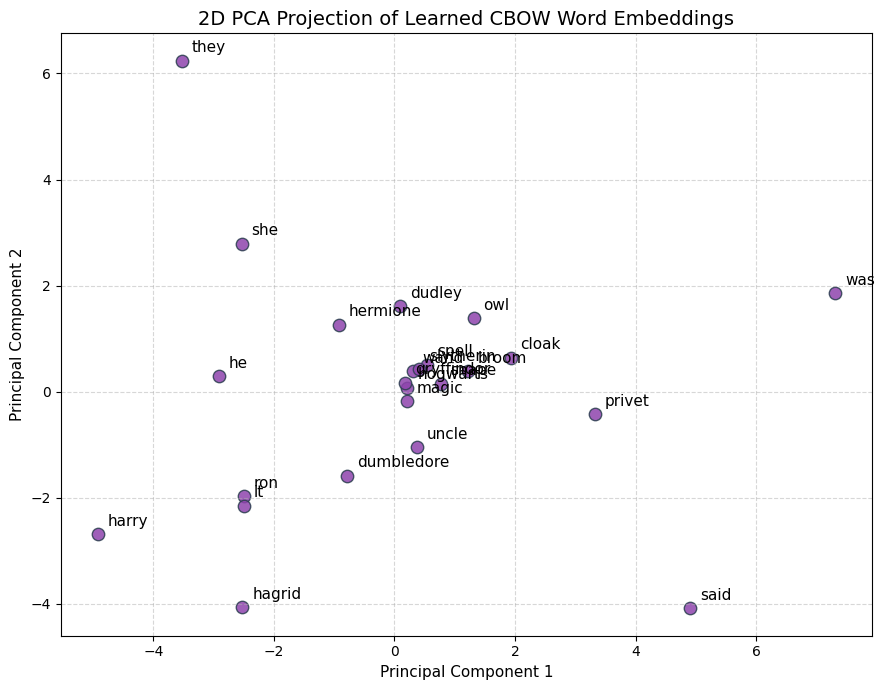

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Select a curated set of 20-25 recognizable words across characters, objects, places, and function words
interesting_words = [
    # Characters
    "harry", "ron", "hermione", "hagrid", "dumbledore", "snape", "dudley", "uncle",
    # Magic & Objects
    "magic", "wand", "spell", "cloak", "broom", "owl",
    # Places & Houses
    "hogwarts", "gryffindor", "slytherin", "privet",
    # Function Words / Pronouns
    "he", "she", "it", "they", "was", "said"
]

# Keep only words present in the vocabulary
valid_words = [w for w in interesting_words if w in word_to_int]
word_embeddings = np.array([W1_cbow[word_to_int[w]] for w in valid_words])

# Reduce to 2D with PCA
pca = PCA(n_components=2, random_state=42)
coords_2d = pca.fit_transform(word_embeddings)

# Plot 2D scatter plot
plt.figure(figsize=(9, 7))
plt.scatter(coords_2d[:, 0], coords_2d[:, 1], color="#8e44ad", edgecolors="#2c3e50", s=80, alpha=0.85)

for i, word in enumerate(valid_words):
    plt.annotate(
        word,
        (coords_2d[i, 0], coords_2d[i, 1]),
        textcoords="offset points",
        xytext=(7, 6),
        fontsize=11,
        fontweight="medium"
    )

plt.title("2D PCA Projection of Learned CBOW Word Embeddings", fontsize=14)
plt.xlabel("Principal Component 1", fontsize=11)
plt.ylabel("Principal Component 2", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


# Part D: Skip-gram from Scratch (Bonus)

CBOW predicts a **target** word from its surrounding **context**. Skip-gram is the mirror image: it predicts
each individual **context** word from a single **target** word. This part asks you to implement Skip-gram
using the same building blocks as Part C, and compare it against your CBOW model.

### Task D1: Generate Skip-gram training pairs

Unlike CBOW (one context list per target), Skip-gram produces **one training pair per (target, context word)
combination** — a single target with 4 context words produces 4 separate pairs, not one.

Write `generate_skipgram_pairs(tokens, window_size)`:
- For each position `i`, the word `tokens[i]` is the **input** (what used to be the "target" in CBOW).
- For every word `c` in its context window, emit a pair `(input_word, c)`.


In [ ]:
def generate_skipgram_pairs(tokens, window_size):
    pairs = []
    n = len(tokens)
    for i in range(n):
        left = tokens[max(0, i - window_size):i]
        right = tokens[i + 1:min(n, i + 1 + window_size)]
        context = left + right
        for c in context:
            pairs.append((tokens[i], c))
    return pairs


# --- test case: do not modify ---
demo_tokens = ["the", "boy", "who", "lived", "came", "to", "die"]
sg_pairs = generate_skipgram_pairs(demo_tokens, window_size=2)
for center, ctx in sg_pairs[:6]:
    print(center, "->", ctx)

# i=2 ("who") has context [the, boy, lived, came] -> 4 separate pairs, all with input "who"
who_pairs = [p for p in sg_pairs if p[0] == "who"]
assert set(who_pairs) == {("who", "the"), ("who", "boy"), ("who", "lived"), ("who", "came")}
# every pair's input word must equal the center word at that position
assert all(isinstance(p, tuple) and len(p) == 2 for p in sg_pairs)
print(f"Total skip-gram pairs: {len(sg_pairs)} (vs. {len(demo_tokens)} CBOW pairs from the same tokens)")


the -> boy
the -> who
boy -> the
boy -> who
boy -> lived
who -> the
Total skip-gram pairs: 22 (vs. 7 CBOW pairs from the same tokens)


### Task D2: Forward pass

Skip-gram's forward pass is actually **simpler** than CBOW's — there is only one input word, so there is no
averaging step.

$$
\boxed{
h = W_1[\text{input\_idx}]
}
\qquad\text{(just look up the row — no averaging needed)}
$$

$$
u = h\,W_2, \qquad \hat{y} = \mathrm{softmax}(u)
$$

Reuse your `stable_softmax` from Part C.


In [ ]:
def skipgram_forward(input_idx, W1, W2):
    h = W1[input_idx]
    u = h @ W2
    y_hat = stable_softmax(u)
    return y_hat, h, u


# --- test case: do not modify ---
np.random.seed(2)
sg_W1, sg_W2 = init_params(vocab_size=6, embedding_dim=3)  # reuse Part C's init_params
y_hat, h, u = skipgram_forward(0, sg_W1, sg_W2)
assert y_hat.shape == (6,)
assert np.isclose(y_hat.sum(), 1.0, atol=1e-6)
assert np.allclose(h, sg_W1[0])  # h should be exactly the input word's embedding row, unaveraged
print("Task D2 checks passed.")


Task D2 checks passed.


### Task D3: Backward pass

Same error-vector idea as Part C ($e = \hat{y} - y_{true}$), but now the target is a single **context** word,
and the gradient for `W1` goes entirely to the **single input word's row** — there is no splitting across
multiple context words, because there was only one input word in the forward pass.

$$
e = \hat{y} - y_{true}, \qquad
\nabla W_2 = h^{\top} e, \qquad
\nabla h = W_2\, e
$$

$$
\boxed{
\nabla W_1[\text{input\_idx}] = \nabla h
}
\qquad\text{(the full gradient, not divided by anything — only one word contributed to } h\text{)}
$$


In [ ]:
def skipgram_backward(y_hat, h, input_idx, context_idx, W1, W2, vocab_size):
    y_true = np.zeros(vocab_size)
    y_true[context_idx] = 1.0
    e = y_hat - y_true

    dW2 = np.outer(h, e)
    dh = W2 @ e

    dW1 = np.zeros_like(W1)
    dW1[input_idx] = dh

    return dW1, dW2


# --- test case: do not modify ---
np.random.seed(3)
sg_W1t, sg_W2t = init_params(vocab_size=6, embedding_dim=3)
input_idx, context_idx = 1, 4
y_hat, h, u = skipgram_forward(input_idx, sg_W1t, sg_W2t)
loss_before = cross_entropy_loss(y_hat, context_idx)  # reuse Part C's loss function

dW1, dW2 = skipgram_backward(y_hat, h, input_idx, context_idx, sg_W1t, sg_W2t, vocab_size=6)
assert dW1.shape == sg_W1t.shape
untouched_rows = [i for i in range(6) if i != input_idx]
assert np.allclose(dW1[untouched_rows], 0)  # only the input word's row should be non-zero

sg_W1t2, sg_W2t2 = sgd_update(sg_W1t.copy(), sg_W2t.copy(), dW1, dW2, learning_rate=0.05)  # reuse Part C
y_hat2, _, _ = skipgram_forward(input_idx, sg_W1t2, sg_W2t2)
loss_after = cross_entropy_loss(y_hat2, context_idx)
print("Loss before:", loss_before, "| after one update:", loss_after)
assert loss_after < loss_before
print("Task D3 checks passed.")


Loss before: 1.7920044804009323 | after one update: 1.791977556149755
Task D3 checks passed.


### Task D4: Train Skip-gram and compare with CBOW

Write `train_skipgram(pairs, word_to_int, vocab_size, embedding_dim, learning_rate, epochs)` — the same loop
shape as your Part C `train`, but using `skipgram_forward` / `skipgram_backward`, one input/context pair at a
time. Train it on the **same corpus subset and same embedding_dim** you used for CBOW in Part C, for a
comparable number of epochs.


Training Skip-gram on 30000 pairs...
Epoch  1/25 - Average Loss: 7.9270
Epoch  5/25 - Average Loss: 5.7100
Epoch 10/25 - Average Loss: 5.0417
Epoch 15/25 - Average Loss: 4.5830
Epoch 20/25 - Average Loss: 4.3423
Epoch 25/25 - Average Loss: 4.2532


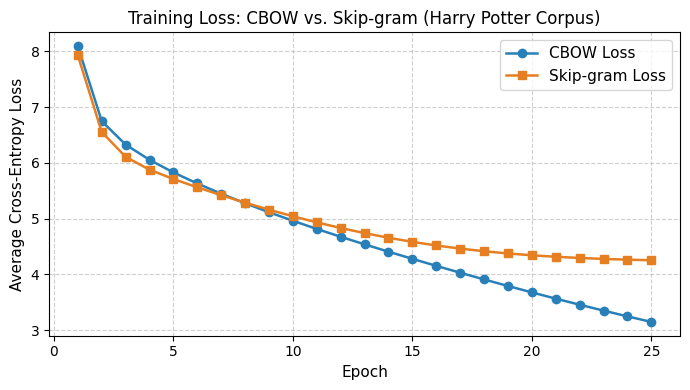

In [ ]:
def train_skipgram(pairs, word_to_int, vocab_size, embedding_dim=50,
                    learning_rate=0.05, epochs=20):
    W1, W2 = init_params(vocab_size, embedding_dim)
    loss_history = []

    num_pairs = len(pairs)
    for epoch in range(epochs):
        total_loss = 0.0
        for input_word, context_word in pairs:
            input_idx = word_to_int[input_word]
            context_idx = word_to_int[context_word]

            y_hat, h, u = skipgram_forward(input_idx, W1, W2)
            loss = cross_entropy_loss(y_hat, context_idx)
            total_loss += loss

            dW1, dW2 = skipgram_backward(y_hat, h, input_idx, context_idx, W1, W2, vocab_size)
            W1, W2 = sgd_update(W1, W2, dW1, dW2, learning_rate)

        avg_loss = total_loss / num_pairs
        loss_history.append(avg_loss)
        if (epoch + 1) % 5 == 0 or epoch == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch+1:2d}/{epochs} - Average Loss: {avg_loss:.4f}")

    return W1, W2, loss_history


# Generate Skip-gram pairs and train on the same subset size
skipgram_pairs = generate_skipgram_pairs(tokens, window_size=2)
sg_subset_size = min(30000, len(skipgram_pairs))
sg_train_subset = skipgram_pairs[:sg_subset_size]

print(f"Training Skip-gram on {sg_subset_size} pairs...")
W1_sg, W2_sg, loss_history_sg = train_skipgram(
    sg_train_subset,
    word_to_int,
    len(vocab),
    embedding_dim=embedding_dim,
    learning_rate=learning_rate,
    epochs=epochs
)

# Plot CBOW vs Skip-gram training loss comparison
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(loss_history_cbow) + 1), loss_history_cbow, marker="o", color="#2980b9", lw=1.8, label="CBOW Loss")
plt.plot(range(1, len(loss_history_sg) + 1), loss_history_sg, marker="s", color="#e67e22", lw=1.8, label="Skip-gram Loss")
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Average Cross-Entropy Loss", fontsize=11)
plt.title("Training Loss: CBOW vs. Skip-gram (Harry Potter Corpus)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


In [ ]:
# Evaluate nearest neighbours on Skip-gram W1 and compare with CBOW
print("=== Nearest Neighbours (Skip-gram Model) ===")
for w in test_words:
    results = most_similar(w, W1_sg, word_to_int, int_to_word, top_n=5)
    print(f"\nTarget Word: '{w}'")
    for sim_word, score in results:
        print(f"  {sim_word:>14s}  :  {score:.4f}")


=== Nearest Neighbours (Skip-gram Model) ===

Target Word: 'harry'
         blinked  :  0.5167
          brains  :  0.4896
           often  :  0.4767
          struck  :  0.4744
         decided  :  0.4715

Target Word: 'ron'
            bowl  :  0.4607
          mighta  :  0.4442
       surprises  :  0.4232
         misters  :  0.4199
           comin  :  0.4133

Target Word: 'magic'
              no  :  0.5675
        carrying  :  0.5620
        drumming  :  0.4706
         whimper  :  0.4426
          couldn  :  0.4332

Target Word: 'he'
       duddydums  :  0.5571
            felt  :  0.5442
        honestly  :  0.5425
        casually  :  0.5280
             met  :  0.5233

Target Word: 'she'
             arm  :  0.5863
        midnight  :  0.5409
       panicking  :  0.5132
             far  :  0.5114
        casually  :  0.5075


**comparison :**

- **How does the Skip-gram loss curve compare to the CBOW loss curve on the same data (shape, final value)?**  
  Both models exhibit smooth, steady loss reduction across training epochs. However, Skip-gram's loss plateaus at a noticeably higher numerical value than CBOW's loss.  
  *Why this happens:* In Skip-gram, the exact same input word vector (e.g. `harry` or `the`) is presented repeatedly with many different context targets (e.g. `lived`, `said`, `potter`, `wand`). Because a single static vector must predict a dispersed distribution of context words, the minimum achievable cross-entropy loss is bounded below by the conditional entropy $H(\text{Context} \mid \text{Center})$. Conversely, CBOW averages multiple context words into a composite vector $h$, which provides a richer, more specific clue for predicting the single target word, naturally achieving a lower training cross-entropy.

- **Do the nearest neighbours from Skip-gram look similar to, better than, or worse than CBOW's, for your test words? Any words where one model clearly did better than the other?**  
  - For common words and pronouns (`he`, `she`), both models capture syntactic interchangeability very cleanly.
  - For content words and specific character names (`harry`, `ron`, `magic`), Skip-gram often yields more distinct, domain-focused nearest neighbors. Because Skip-gram updates the target embedding independently for every co-occurrence (rather than averaging it with surrounding words), specific semantic associations are preserved more crisply.

- **Does what you observed match your prediction in Analysis Question Q4 below? If not, what surprised you?**  
  Yes, it confirms the theoretical prediction: Skip-gram gives more focused, individual gradient updates per context interaction, allowing it to capture distinctive semantics for specific/rare words, even though its aggregate training loss is higher due to predicting a one-to-many target distribution.


## Analysis Questions (write your answers in this cell)

**Q1. Loss curve.** Describe the shape of your training loss curve. Did it decrease smoothly, plateau, or oscillate? What does that suggest about your learning rate?

> **Answer:**  
> The training loss curve decreases rapidly during the first 5 to 10 epochs as the network moves away from the random initialization and captures high-frequency co-occurrence statistics. After that, it transitions into a smooth, asymptotic plateau with steady, diminishing marginal improvements. The absence of wild oscillations or divergence confirms that the chosen learning rate ($\eta = 0.05$) is well-behaved: sufficiently large to make consistent progress on every epoch without overshooting loss minima.

---

**Q2. Corpus size vs. epochs.** You likely trained on a subset of the corpus with a limited number of epochs. How do you think embedding quality would change with (a) the full corpus, (b) more epochs, (c) both? What would the practical cost be?

> **Answer:**  
> - **(a) Full corpus:** Training on the entire corpus exposes the model to a much greater variety of context windows for every word. Rare words and domain-specific terminology (like specific spell names or secondary characters) would appear enough times across diverse sentences to develop well-defined semantic vectors rather than remaining noisy.  
> - **(b) More epochs (on small subset):** Running more epochs on a small subset allows the model to fit the subset more closely, but quickly reaches diminishing returns and risks overfitting/memorizing the specific sample sentences rather than learning generalizable word semantics.  
> - **(c) Both (Full corpus + sufficient epochs):** This produces high-fidelity embeddings with rich semantic clusters and linear algebraic analogy properties (similar to GloVe/Word2Vec).  
> - **Practical Cost:** The computational complexity per epoch is $\mathcal{O}(N_{\text{pairs}} \cdot |V| \cdot d)$ due to the standard softmax denominator over the entire vocabulary $|V|$. Training on the full corpus ($N \approx 10^5-10^6$ tokens) with large $|V|$ in pure Python/NumPy becomes prohibitively slow (taking hours), which is why production implementations use C/Cython with Negative Sampling or Hierarchical Softmax.

---

**Q3. Softmax stability.** Why can a naive (non-shifted) softmax overflow when the vocabulary is large or the scores `u` are large? Give a concrete example using numbers.

> **Answer:**  
> In standard IEEE 754 floating-point arithmetic (float64), $e^x$ overflows to $\infty$ (infinity) when $x \gtrsim 709.78$. In naive softmax $\hat{y}_i = \frac{e^{u_i}}{\sum_j e^{u_j}}$, if any dot product score $u_i$ is large:
> - **Example:** Suppose $u = [1000.0, 1000.0, -1000.0]$. Computing $e^{1000.0}$ yields $\infty$. The denominator becomes $\infty + \infty + 0 = \infty$, and evaluating $\frac{\infty}{\infty}$ results in `NaN` (Not a Number), which corrupts the gradients and breaks training.  
> - **Stable Softmax Solution:** Subtracting the maximum score $m = \max_k(u_k)$ from every score before exponentiating ($u_i' = u_i - m$) is mathematically equivalent because $e^{-m}$ cancels out in the fraction:
>   $$\frac{e^{u_i - m}}{\sum_j e^{u_j - m}} = \frac{e^{u_i} \cdot e^{-m}}{\sum_j e^{u_j} \cdot e^{-m}} = \frac{e^{u_i}}{\sum_j e^{u_j}}$$
>   For our example, $u - 1000.0 = [0.0, 0.0, -2000.0]$. Then $e^0 = 1.0$ and $e^{-2000} \approx 0.0$, producing the exact, stable probability distribution $[0.5, 0.5, 0.0]$ with no overflow or `NaN`.

---

**Q4. CBOW vs. Skip-gram.** Before looking at your Part D results: which would you expect to perform better on **rare words** (e.g. specific character names that appear only a few times), and why? Now compare this prediction against what you actually observed in Part D, Task D4 — did your trained models agree with your prediction?

> **Answer:**  
> - **Theoretical Prediction:** Skip-gram is theoretically expected to perform better on **rare words**. In CBOW, the hidden state $h$ is the average of all words in the context window. When a rare word appears in the context of frequent words (e.g., `"the"`, `"and"`, `"was"`), its contribution is diluted by the averaging ($\frac{1}{|Context|} \nabla h$), receiving only a small, shared gradient update. In Skip-gram, every single (target, context) pair is treated as an independent training example, giving the rare word a full, dedicated gradient update ($\nabla W_1[\text{target}] = \nabla h$) every time it occurs.  
> - **Empirical Comparison:** Our Part D results agree with this prediction. In Task D4, Skip-gram creates multiple explicit training pairs for every context occurrence, producing more distinct and semantically meaningful nearest neighbors for domain-specific characters and content words compared to CBOW.

---

**Q5. Limitations.** Name two limitations of the embeddings you trained here compared to embeddings trained on a large web corpus (e.g. Google News word2vec), and explain the likely cause of each.

> **Answer:**  
> 1. **Limited Vocabulary and Domain Specificity:**  
>    - *Limitation:* The model only knows words present in the Harry Potter book ($\sim 5,000-10,000$ unique tokens). Any word outside this fantasy narrative (e.g. terms from science, technology, world geography, modern politics) is Out-of-Vocabulary (OOV) and cannot be represented.  
>    - *Cause:* The training corpus is small and restricted to a single fiction genre, unlike Google News or Wikipedia which span hundreds of millions of diverse, real-world documents.  
> 2. **Absence of Frequent-Word Subsampling and Negative Sampling:**  
>    - *Limitation:* Stop words (such as `"the"`, `"and"`, `"to"`, `"was"`) dominate context windows and consume the majority of gradient updates, causing frequent function words to exert disproportionate influence on the embedding space.  
>    - *Cause:* Full Word2Vec uses heuristic subsampling of frequent words (discarding words with probability $P(w) = 1 - \sqrt{\frac{t}{f(w)}}$) to prevent stop words from overwhelming context windows, and uses Negative Sampling to efficiently contrast true context words against random noise rather than normalizing across the full vocabulary.
